# QShield: Quantum Support Vector Machine


In [2]:
# Import preprocessing utilities and evaluation metrics

import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

In [3]:
# Import Qiskit quantum machine learning components

from qiskit.circuit.library import ZZFeatureMap

from qiskit_machine_learning.kernels import (
    FidelityQuantumKernel
)

from qiskit_machine_learning.algorithms import (
    QSVC
)

## Load Quantum Dataset

In [5]:
# Load reduced fraud dataset prepared for quantum experiments

df = pd.read_csv(
    "/Users/srinidhinunna/Desktop/HighQ/data/quantum_dataset_medium.csv"
)

print(df.shape)

(1000, 14)


## Feature Selection

In [7]:
# Select fraud prediction features

features = [
    "amount",
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest",
    "balance_error_orig",
    "balance_error_dest",
    "amount_ratio",
    "type"
]

X = df[features]

y = df["isFraud"]

## Data Standardization

In [9]:
# Standardize feature values before quantum encoding

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

## Dimensionality Reduction

In [11]:
# Reduce features to four principal components corresponding to four qubits

pca = PCA(
    n_components=4
)

X_pca = pca.fit_transform(X_scaled)

print(
    "Explained Variance:",
    round(
        pca.explained_variance_ratio_.sum(),
        4
    )
)

Explained Variance: 0.8968


In [12]:
# Create stratified train-test split for quantum experiments

X_train, X_test, y_train, y_test = train_test_split(
    X_pca,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

## Quantum Feature Map

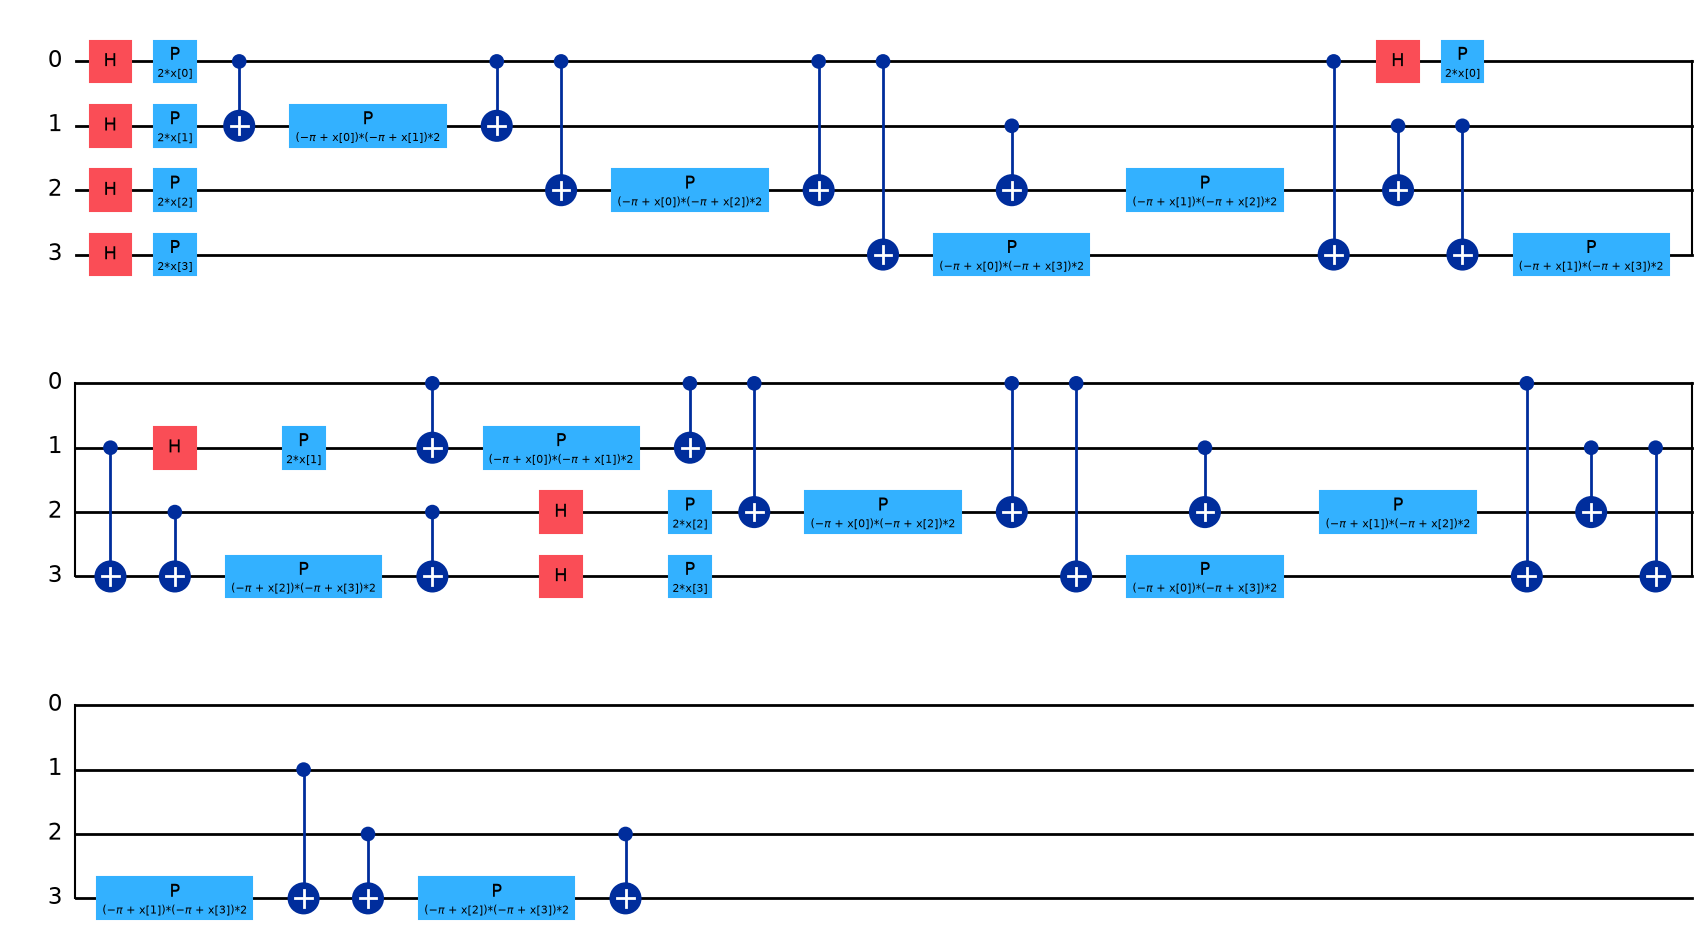

In [14]:
from qiskit.circuit.library import zz_feature_map

# Construct ZZFeatureMap circuit for quantum data embedding
feature_map = zz_feature_map(
    feature_dimension=4,
    reps=2
)

# Draw the circuit
feature_map.draw("mpl")

## Quantum Kernel Construction

In [16]:
# Create fidelity-based quantum kernel

quantum_kernel = FidelityQuantumKernel(
    feature_map=feature_map
)

## QSVM Configuration

In [18]:
# Initialize Quantum Support Vector Machine classifier

qsvc = QSVC(
    quantum_kernel=quantum_kernel
)

## QSVM Training

In [20]:
# Train the quantum support vector machine

qsvc.fit(
    X_train,
    y_train
)

print("Training Complete")

Training Complete


## Inference

In [22]:
# Predict fraud labels using the trained quantum model

predictions = qsvc.predict(
    X_test
)

## Quantum Model Evaluation

In [24]:
# Compute QSVM evaluation metrics

accuracy = accuracy_score(
    y_test,
    predictions
)

precision = precision_score(
    y_test,
    predictions
)

recall = recall_score(
    y_test,
    predictions
)

f1 = f1_score(
    y_test,
    predictions
)

print("Accuracy :", round(accuracy,4))
print("Precision:", round(precision,4))
print("Recall   :", round(recall,4))
print("F1 Score :", round(f1,4))

Accuracy : 0.79
Precision: 0.8625
Recall   : 0.69
F1 Score : 0.7667


In [25]:
# Save QSVM results for final comparison tables

results = pd.DataFrame({
    "Metric":[
        "Accuracy",
        "Precision",
        "Recall",
        "F1"
    ],
    "Value":[
        accuracy,
        precision,
        recall,
        f1
    ]
})

results.to_csv(
    "/Users/srinidhinunna/Desktop/HighQ/qsvm_results.csv",
    index=False
)

results

,Metric,Value
0,Accuracy,0.790000
1,Precision,0.862500
2,Recall,0.690000
3,F1,0.766667


# Key Findings

1. Fraud transactions were encoded into a four-dimensional quantum feature space.
2. A fidelity-based quantum kernel was used to estimate similarity between transactions.
3. QSVM performance was evaluated using the same metrics as classical baselines.
4. Results will be compared against Logistic Regression, Random Forest, XGBoost, and Classical SVM.
5. Future work includes execution on IBM Quantum hardware and noise-aware evaluation.

In [27]:
print("Dataset Shape:")
print(df.shape)

print("\nClass Distribution:")
print(df["isFraud"].value_counts())

Dataset Shape:
(1000, 14)

Class Distribution:
isFraud
0    500
1    500
Name: count, dtype: int64


In [28]:
print("Original Feature Shape:")
print(X.shape)

print("\nPCA Feature Shape:")
print(X_pca.shape)

print("\nExplained Variance:")
print(pca.explained_variance_ratio_)

print(
    "\nTotal Explained Variance:",
    pca.explained_variance_ratio_.sum()
)

Original Feature Shape:
(1000, 9)

PCA Feature Shape:
(1000, 4)

Explained Variance:
[0.35723981 0.30358675 0.14382386 0.0921642 ]

Total Explained Variance: 0.8968146282977929


In [29]:
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)

print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (800, 4)
X_test : (200, 4)
y_train: (800,)
y_test : (200,)


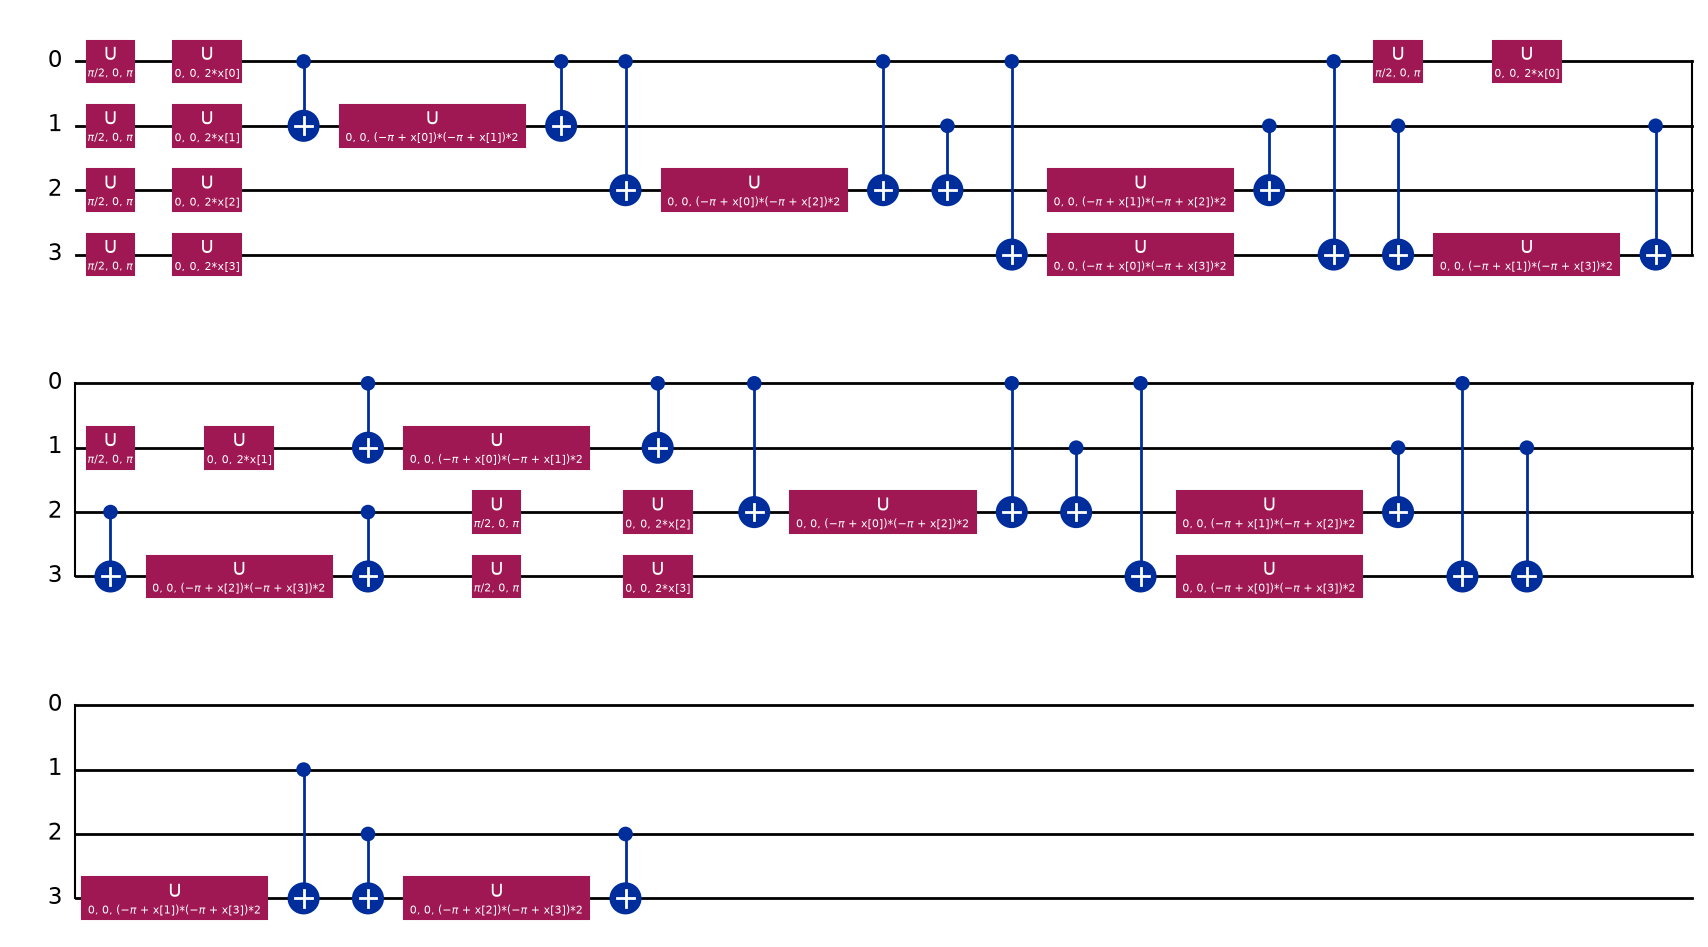

In [30]:
feature_map.decompose().draw("mpl")

In [31]:
print(type(quantum_kernel))

<class 'qiskit_machine_learning.kernels.fidelity_quantum_kernel.FidelityQuantumKernel'>


In [32]:
print("Support Vectors:")
print(len(qsvc.support_))

Support Vectors:
418


In [33]:
print(predictions[:20])

[1 0 0 0 1 1 1 0 0 0 1 1 1 0 0 0 1 0 1 0]


In [34]:
accuracy = accuracy_score(
    y_test,
    predictions
)

precision = precision_score(
    y_test,
    predictions
)

recall = recall_score(
    y_test,
    predictions
)

f1 = f1_score(
    y_test,
    predictions
)

print("=" * 50)
print("QSVM RESULTS")
print("=" * 50)

print("Accuracy :", round(accuracy,4))
print("Precision:", round(precision,4))
print("Recall   :", round(recall,4))
print("F1 Score :", round(f1,4))

QSVM RESULTS
Accuracy : 0.79
Precision: 0.8625
Recall   : 0.69
F1 Score : 0.7667


In [35]:
classical_f1 = 0.999696

print(
    "Classical Best F1:",
    classical_f1
)

print(
    "QSVM F1:",
    round(f1,4)
)

print(
    "Difference:",
    round(classical_f1 - f1,4)
)

Classical Best F1: 0.999696
QSVM F1: 0.7667
Difference: 0.233
